# Phase 3: Richer data before deeper models (Steps 1-2)

Phase 2 ended with a pooled Random Forest on 43 screened summary-file features plus time and zone features. Most of the remaining error comes from things that file can't describe: **how big the place is, what it offers, and how guests rate it**. Before adding neural networks, we feed the models better data and measure each step on the same host-grouped test set:

| Step | Adds | Source |
|---|---|---|
| 0 | Phase 2 features (snapshot + time + zone) | summary files |
| **1** | Guest capacity, bedrooms, beds, bathrooms, property type, 30 amenity groups, review scores, superhost | detailed Inside Airbnb exports (`data/detailed/`) |
| **2** | Location context: distance to 14 demand drivers, nearby supply, and the local Airbnb market price | coordinates + training prices; Zillow market data when available |

Each step is tested with four models: **Lasso**, **Random Forest**, **LightGBM** and **CatBoost**. LightGBM and CatBoost are gradient-boosting libraries that handle missing values natively and usually lead on tabular data.

**Rules carried over from earlier phases:** the same pre-check runs on every row, the split is **grouped by host**, and any column that contains or results from the price is excluded.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA, OUT, SEED = Path("../data"), Path("../interface"), 42
sys.path.insert(0, "../src")
import pricing_features as pf
import enriched_features as ef

official = pd.read_csv(DATA / "neighbourhoods.csv")["neighbourhood"]
geo = pf.load_geo(DATA / "neighbourhoods.geojson")
NEIGHBOURHOODS = pf.model_neighbourhoods(official)
_js = (OUT / "data.js").read_text(); BUNDLE = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
print("lightgbm", lgb.__version__)

lightgbm 4.7.0


## 1. Load the detailed exports and pre-check them

The detailed files describe the same listings as the summary files with 90 columns instead of 19. June and September carry prices; March has none, so it only contributes to tenure (how long a listing has been live).

In [2]:
DETAILED = [("2026Q2", "Jun 2026", "listings_detailed_2026Q2_jun.csv.gz"),
            ("2026Q3", "Sep 2026", "listings_detailed_2026Q3_sep.csv.gz")]
frames, supply, reports = [], [], {}
for q, label, f in DETAILED:
    raw = ef.load_detailed(DATA / "detailed" / f)
    allrows, _ = pf.precheck(raw, official, geo, require_price=False)     # every listing, for supply density
    allrows["quarter"] = q; supply.append(allrows[["quarter", "latitude", "longitude"]])
    d, rep = pf.precheck(raw, official, geo)                               # priced rows for modelling
    d["quarter"], d["q_label"] = q, label
    reports[label] = rep.set_index("check")["rows"]
    frames.append(d)
A = pd.concat(frames, ignore_index=True)
SUPPLY = pd.concat(supply, ignore_index=True)
print(A.groupby("q_label").size().to_dict(), "priced rows after pre-check")
pd.DataFrame(reports)

{'Jun 2026': 3562, 'Sep 2026': 3477} priced rows after pre-check


,Jun 2026,Sep 2026
check,,
Duplicate listing IDs,0,0
Missing price (inactive listing),685,882
Price outside $30-$2000,129,6
"Exact duplicate posting (same host, title, location, price, rules)",2,3
Neighbourhood not in official list,0,0
Coordinates outside their neighbourhood boundary,0,0
Reviews in last 12 months > total reviews,0,0
Reviews per month missing (no reviews yet),577,482
Reviews per month > 0 with zero reviews,0,0


## 2. Leakage audit of the new columns

A column can't be a feature if it contains the price, is computed from it, or is an *outcome* of the price (how booked the listing is). The check below shows why each excluded column is excluded.

In [3]:
lp = np.log(A["price"])
quote = pd.to_numeric(A["price_quote_price_per_night"], errors="coerce")
audit = pd.DataFrame([
    ("price_quote_* (5 columns)", f"{(quote.round(0) == A['price'].round(0)).mean():.0%} identical to price", "Exclude: it is the price"),
    ("estimated_revenue_l365d", f"Spearman {A['estimated_revenue_l365d'].corr(lp, method='spearman'):.2f} with log price", "Exclude: computed as price × occupancy"),
    ("estimated_occupancy_l365d", f"Spearman {A['estimated_occupancy_l365d'].corr(lp, method='spearman'):.2f}", "Exclude: bookings respond to the price (reverse causality)"),
    ("availability_30 / 60 / 90 / eoy", f"Spearman {A['availability_30'].corr(lp, method='spearman'):.2f} (30-day)", "Exclude: short-term availability = bookings"),
    ("host_since, host_response_rate, instant_bookable", f"{A['host_since'].notna().mean():.0%} filled", "Unusable: empty in this export"),
], columns=["column", "evidence", "decision"])
assert not (ef.LEAKY & set(["accommodates"]))
audit

,column,evidence,decision
0,price_quote_* (5 columns),100% identical to price,Exclude: it is the price
1,estimated_revenue_l365d,Spearman 0.39 with log price,Exclude: computed as price × occupancy
2,estimated_occupancy_l365d,Spearman 0.08,Exclude: bookings respond to the price (revers...
3,availability_30 / 60 / 90 / eoy,Spearman 0.15 (30-day),Exclude: short-term availability = bookings
4,"host_since, host_response_rate, instant_bookable",0% filled,Unusable: empty in this export


## 3. Step 1: detailed listing attributes

* **Size:** `accommodates`, `bedrooms_d` (detailed bedrooms; title regex only as fallback), `beds`, `baths` and `baths_shared` parsed from `bathrooms_text` ("1.5 shared baths").
* **Property type:** 27 raw types grouped into 12 (rental unit, condo, house, serviced apt, hotel, room in house, …).
* **Amenities:** 30 interpretable groups (in-unit washer, free parking, gym, view, self check-in, …) plus the amenity count. Groups are stable across quarters, where raw strings like "65 inch HDTV" are not.
* **Reviews:** the 7 review scores and a flag for listings that have none.
* **Host:** superhost, identity verified, description length.

Missing values stay missing (`NaN`): LightGBM and CatBoost learn what "unknown" means, and Lasso and Random Forest get a median fill plus a missing-value indicator.

In [4]:
PROPS = sorted(set(ef.PROPERTY_GROUPS.values())) + ["other"]
D1 = ef.detailed_features(A, PROPS)
cover = pd.DataFrame({"filled_%": (D1.notna().mean() * 100).round(1),
                      "spearman_vs_logprice": D1.corrwith(lp, method="spearman").round(3)})
print(D1.shape[1], "Step 1 features")
cover.sort_values("spearman_vs_logprice", key=abs, ascending=False).head(25)

58 Step 1 features


,filled_%,spearman_vs_logprice
accommodates,100.0,0.602
baths_shared,100.0,-0.545
beds,93.9,0.500
prop_room_in_unit,100.0,-0.446
bedrooms_d,90.2,0.391
am_tv,100.0,0.365
prop_room_in_house,100.0,-0.318
baths,99.2,0.258
prop_rental_unit,100.0,0.255
am_crib,100.0,0.248


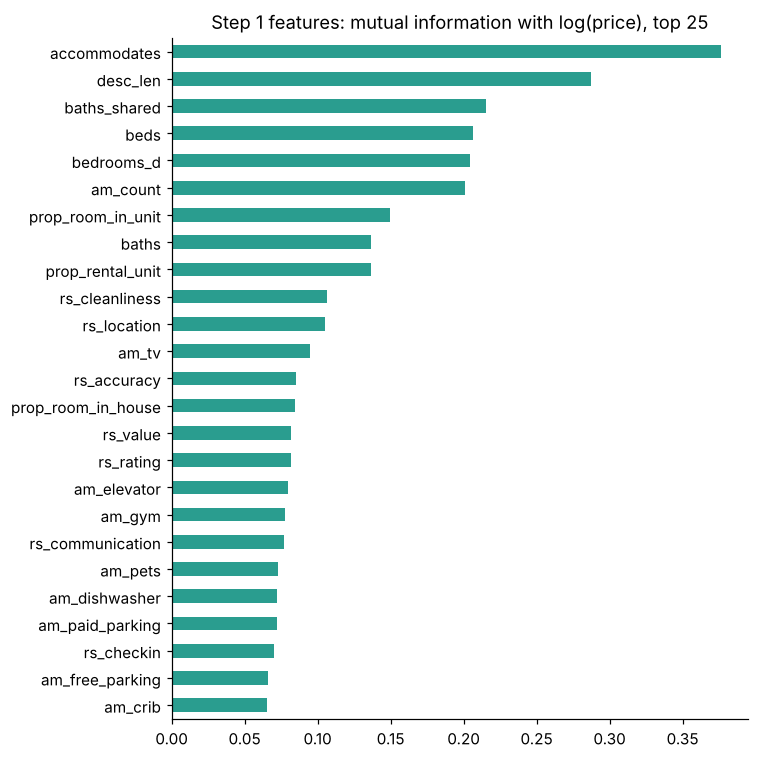

Size variables overlap (Spearman):
              accommodates  bedrooms_d  beds  baths
accommodates          1.00        0.76  0.85   0.39
bedrooms_d            0.76        1.00  0.78   0.52
beds                  0.85        0.78  1.00   0.41
baths                 0.39        0.52  0.41   1.00
VIF of the size block: {'accommodates': 5.2, 'bedrooms_d': 3.3, 'beds': 4.4, 'baths': 1.5}


In [5]:
mi = pd.Series(mutual_info_regression(D1.fillna(D1.median()), lp, random_state=SEED), D1.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
mi.tail(25).plot.barh(ax=ax, color="#2a9d8f"); ax.set_title("Step 1 features: mutual information with log(price), top 25")
plt.tight_layout(); plt.show()
size = ["accommodates", "bedrooms_d", "beds", "baths"]
print("Size variables overlap (Spearman):"); print(D1[size].corr(method="spearman").round(2))
print("VIF of the size block:", pf.vif(D1[size].fillna(D1[size].median())).round(1).to_dict())

**Reading.** Guest capacity, bedrooms and beds overlap strongly, which is expected (VIF around 3-5, below the cut-off of 10). Tree models use them together without trouble; Lasso spreads the weight across them. All four are kept because each adds detail: a 2-bedroom that sleeps 6 differs from one that sleeps 3.

## 4. Step 2: location context

1. **Distance to 14 demand drivers:** airport, convention center, Seaport, stations, TD Garden, Fenway Park, universities and the Longwood hospitals. Coordinates are approximate (100-200 m), plenty for distances in km.
2. **Nearby supply:** listings of the same quarter within 300 m and 1 km, priced or not.
3. **Local Airbnb market price:** the median log price of the 15 nearest listings **from other hosts**, overall and for the same room type. It is computed **only from training rows**, so test prices never leak into it. This is the comparable-listings check a host does by hand.
4. **Housing market (Zillow ZHVI):** loaded from `data/market/` when present. This session's network policy blocks Zillow and the Census API, so the step is skipped below rather than filled with invented numbers.

In [6]:
L2 = ef.landmark_features(A)
S2 = ef.density_features(A, SUPPLY)
zhvi = ef.load_zillow_neighbourhood(DATA / "market" / "Neighborhood_zhvi.csv", months=["2026-06", "2026-09"])
print("Zillow market data:", "loaded" if zhvi is not None else "not available (data/market/Neighborhood_zhvi.csv missing): step skipped")
L2.join(S2).describe().T[["mean", "min", "max"]].round(2).head(18)

Zillow market data: not available (data/market/Neighborhood_zhvi.csv missing): step skipped


,mean,min,max
d_boston_common,3.91,0.10,14.37
d_logan_airport,7.34,1.62,17.63
d_fenway_park,3.90,0.15,12.70
d_convention_ctr,4.52,0.20,14.19
d_seaport,4.76,0.08,14.97
d_south_station,4.15,0.11,14.45
d_td_garden,4.67,0.08,15.63
d_back_bay_station,3.56,0.04,13.29
d_faneuil_hall,4.43,0.04,15.20
d_mit,4.40,1.01,14.20


## 5. Time and zone features (from Phase 2)

Quarter, tenure (earlier quarters live, counted across all four summary snapshots), days since the last review, distance rings and the 8 geographic zones whose centres Phase 2 exported.

In [7]:
seen = {}
for i, (q, f) in enumerate([("2025Q4", "listings_2025Q4_dec.csv"), ("2026Q1", "listings_2026Q1_mar.csv"),
                            ("2026Q2", "listings_2026Q2_jun.csv"), ("2026Q3", "listings_2026Q3_sep.csv")]):
    for lid in pd.read_csv(DATA / "quarterly" / f, usecols=["id"])["id"]:
        seen.setdefault(lid, set()).add(i)
q_idx = A["quarter"].map({"2026Q2": 2, "2026Q3": 3})
T = pd.DataFrame(index=A.index)
T["q_sep"] = (A["quarter"] == "2026Q3").astype(int)
T["tenure_q"] = [sum(j < q for j in seen.get(i, set())) for i, q in zip(A["id"], q_idx)]
T["days_since_review"] = (pd.to_datetime(A["last_scraped"]) - pd.to_datetime(A["last_review"])).dt.days.clip(0, 1095).fillna(1095)
centers = np.array(BUNDLE["quarterly"]["zones"]["centers_km"])
P = ef.km_coords(A["latitude"], A["longitude"])
zone = np.argmin(((P[:, None, :] - centers[None]) ** 2).sum(-1), axis=1)
dist = np.sqrt((P ** 2).sum(1))
T["ring_core"], T["ring_inner"], T["ring_outer"] = (dist < 2).astype(int), ((dist >= 2) & (dist <= 5)).astype(int), (dist > 5).astype(int)
for z in range(len(centers)):
    T[f"zone_{z}"] = (zone == z).astype(int)
B0 = pf.build_features(A, NEIGHBOURHOODS)
print("Phase 2 feature set:", B0.shape[1] + T.shape[1], "columns")

Phase 2 feature set: 57 columns


## 6. Split and the market-price feature

The same host-grouped 80/20 split is used for every step. The local-market feature is then built: training rows from other training hosts, test rows from training hosts only.

In [8]:
y = np.log(A["price"].values)
groups = A["host_id"].values
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(A, y, groups))
assert not set(groups[tr]) & set(groups[te])
TRd, TEd = A.iloc[tr], A.iloc[te]
K2 = pd.concat([ef.knn_market_price(TRd, TRd), ef.knn_market_price(TEd, TRd)]).loc[A.index].astype(float)
print("train", len(tr), "test", len(te), "| hosts", len(set(groups[tr])), "/", len(set(groups[te])))
print("local market price vs actual (test, Spearman):", round(pd.Series(K2.iloc[te, 0].values).corr(pd.Series(y[te]), method="spearman"), 3))

SETS = {
    "0. Phase 2 features": pd.concat([B0, T], axis=1),
    "1. + detailed attributes": pd.concat([B0, T, D1], axis=1),
    "2. + location context": pd.concat([B0, T, D1, L2, S2, K2], axis=1),
}
FAMILY = {}
for c in B0.columns: FAMILY[c] = "Location (neighbourhood, coordinates)" if c.startswith("nb_") or c in ("latitude", "longitude", "dist_km") else "Snapshot listing features"
for c in T.columns: FAMILY[c] = "Time and zone"
for c in D1.columns:
    FAMILY[c] = ("Amenities" if c.startswith("am_") else "Review scores" if c.startswith("rs_") or c == "has_review_scores"
                 else "Property type" if c.startswith("prop_") else "Size (guests, beds, baths)" if c in ("accommodates", "bedrooms_d", "beds", "baths", "baths_shared")
                 else "Host and description")
for c in list(L2.columns) + list(S2.columns): FAMILY[c] = "Landmarks and supply"
for c in K2.columns: FAMILY[c] = "Local Airbnb market price"
{k: v.shape[1] for k, v in SETS.items()}

train 5710 test 1329 | hosts 1017 / 255
local market price vs actual (test, Spearman): 0.283


{'0. Phase 2 features': 57,
 '1. + detailed attributes': 115,
 '2. + location context': 135}

## 7. The ladder: each step × four models

LightGBM is tuned once with host-grouped 5-fold CV on the training rows of the full feature set (a small grid), and the same settings are used for every step. Random Forest uses the Phase 1 settings with more depth allowed, because there are now many more informative features.

In [9]:
Xfull = SETS["2. + location context"]
grid = [dict(num_leaves=15, min_child_samples=30), dict(num_leaves=31, min_child_samples=20), dict(num_leaves=63, min_child_samples=20)]
cv_res = {}
for g in grid:
    errs = []
    for a, b in GroupKFold(5).split(Xfull.iloc[tr], y[tr], groups[tr]):
        m = lgb.LGBMRegressor(n_estimators=900, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                              reg_lambda=1.0, random_state=SEED, verbose=-1, **g)
        m.fit(Xfull.iloc[tr].iloc[a], y[tr][a])
        errs.append(np.sqrt(np.mean((m.predict(Xfull.iloc[tr].iloc[b]) - y[tr][b]) ** 2)))
    cv_res[str(g)] = np.mean(errs)
LGB_BEST = eval(min(cv_res, key=cv_res.get))
print({k: round(v, 4) for k, v in cv_res.items()}, "->", LGB_BEST)

{"{'num_leaves': 15, 'min_child_samples': 30}": np.float64(0.3516), "{'num_leaves': 31, 'min_child_samples': 20}": np.float64(0.3496), "{'num_leaves': 63, 'min_child_samples': 20}": np.float64(0.3533)} -> {'num_leaves': 31, 'min_child_samples': 20}


In [10]:
def make(name):
    if name == "Lasso":
        return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("s", StandardScaler()),
                         ("m", LassoCV(alphas=np.logspace(-4, -1, 25), max_iter=50000))])
    if name == "Random Forest":
        return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.4, random_state=SEED, n_jobs=-1))])
    if name == "LightGBM":
        return lgb.LGBMRegressor(n_estimators=900, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                                 reg_lambda=1.0, random_state=SEED, verbose=-1, **LGB_BEST)
    if name == "CatBoost":
        return CatBoostRegressor(iterations=1500, learning_rate=0.04, depth=6, l2_leaf_reg=3, random_seed=SEED, verbose=0)

def score(yt, yp, q):
    t, p = np.exp(yt), np.exp(yp)
    out = {"MAE_$": mean_absolute_error(t, p), "R2_log": r2_score(yt, yp), "within_20%": np.mean(np.abs(p - t) / t <= .2) * 100}
    for lab in ["Jun 2026", "Sep 2026"]:
        m = q == lab
        out["MAE_" + lab[:3]] = mean_absolute_error(t[m], p[m])
    return out

MODELS = ["Lasso", "Random Forest", "LightGBM", "CatBoost"]
rows, fitted = [], {}
qte = A["q_label"].values[te]
for sname, X in SETS.items():
    for mname in MODELS:
        t0 = time.time(); m = make(mname).fit(X.iloc[tr], y[tr])
        p = m.predict(X.iloc[te]); fitted[(sname, mname)] = m
        rows.append({"step": sname, "model": mname, **score(y[te], p, qte), "fit_s": time.time() - t0})
ladder = pd.DataFrame(rows)
ladder.pivot(index="step", columns="model", values="MAE_$").round(1)

model,CatBoost,Lasso,LightGBM,Random Forest
step,,,,
0. Phase 2 features,135.1,141.1,136.3,134.7
1. + detailed attributes,101.1,115.1,99.2,109.9
2. + location context,102.6,116.3,98.1,109.3


In [11]:
ladder.pivot(index="step", columns="model", values="R2_log").round(3)

model,CatBoost,Lasso,LightGBM,Random Forest
step,,,,
0. Phase 2 features,0.567,0.550,0.571,0.588
1. + detailed attributes,0.749,0.702,0.760,0.734
2. + location context,0.746,0.696,0.762,0.733


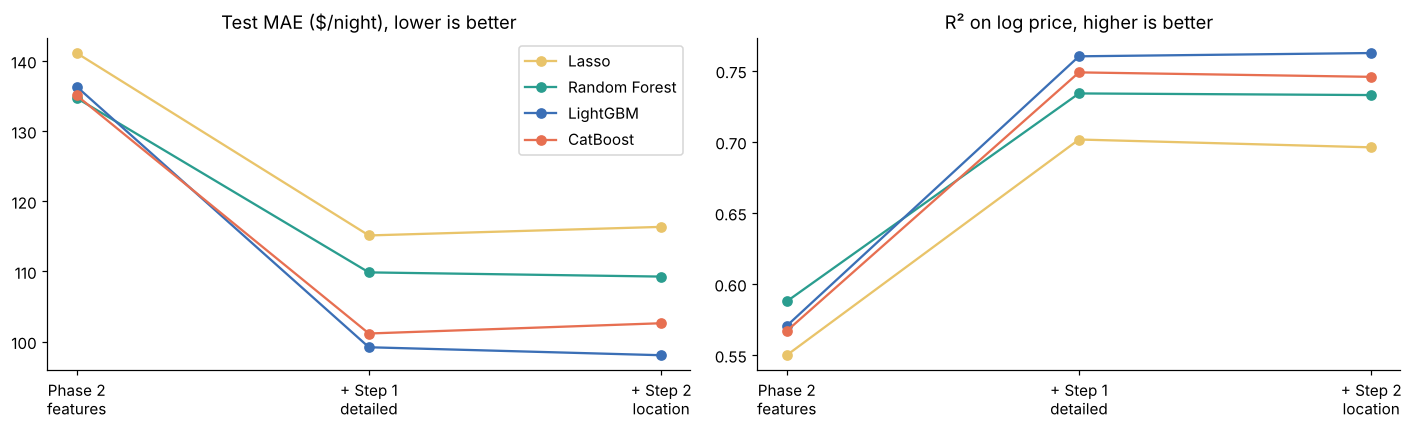

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = {"Lasso": "#e9c46a", "Random Forest": "#2a9d8f", "LightGBM": "#3b6fb6", "CatBoost": "#e76f51"}
steps = list(SETS)
for mname in MODELS:
    v = ladder[ladder["model"] == mname].set_index("step").loc[steps]
    ax[0].plot(range(3), v["MAE_$"], marker="o", color=colors[mname], label=mname)
    ax[1].plot(range(3), v["R2_log"], marker="o", color=colors[mname], label=mname)
for a, t in zip(ax, ["Test MAE ($/night), lower is better", "R² on log price, higher is better"]):
    a.set_xticks(range(3), ["Phase 2\nfeatures", "+ Step 1\ndetailed", "+ Step 2\nlocation"]); a.set_title(t)
ax[0].legend(); plt.tight_layout(); plt.show()

### Robustness check: 5-fold host-grouped CV

A single test split can't separate a $1 difference from noise. Below, LightGBM is re-run on **all** priced rows with host-grouped 5-fold CV. The local-market feature is rebuilt inside every fold from that fold's training rows only. Step 2 is also split into its two parts to see which one carries any gain.

In [13]:
CV_SETS = {
    "0. Phase 2 features": lambda K: pd.concat([B0, T], axis=1),
    "1. + detailed attributes": lambda K: pd.concat([B0, T, D1], axis=1),
    "2a. + landmarks and supply": lambda K: pd.concat([B0, T, D1, L2, S2], axis=1),
    "2. + location context (all)": lambda K: pd.concat([B0, T, D1, L2, S2, K], axis=1),
}
fold_rows = []
for k, (a, b) in enumerate(GroupKFold(5).split(A, y, groups)):
    Ka = pd.concat([ef.knn_market_price(A.iloc[a], A.iloc[a]), ef.knn_market_price(A.iloc[b], A.iloc[a])]).loc[A.index].astype(float)
    for sname, build in CV_SETS.items():
        X = build(Ka)
        m = make("LightGBM").fit(X.iloc[a], y[a]); p = m.predict(X.iloc[b])
        fold_rows.append({"fold": k, "step": sname, "MAE_$": mean_absolute_error(np.exp(y[b]), np.exp(p)), "RMSE_log": np.sqrt(np.mean((p - y[b]) ** 2))})
cvl = pd.DataFrame(fold_rows)
cv_summary = cvl.groupby("step", sort=False).agg(MAE_mean=("MAE_$", "mean"), MAE_std=("MAE_$", "std"), RMSE_log_mean=("RMSE_log", "mean"), RMSE_log_std=("RMSE_log", "std"))
# paired comparison: same folds, so look at the per-fold difference to the previous step
piv = cvl.pivot(index="fold", columns="step", values="MAE_$")[list(CV_SETS)]
paired = pd.DataFrame({"mean_change_$": piv.diff(axis=1).mean(), "folds_improved": (piv.diff(axis=1) < 0).sum()}).iloc[1:]
display(cv_summary.round(3)); paired.round(2)

,MAE_mean,MAE_std,RMSE_log_mean,RMSE_log_std
step,,,,
0. Phase 2 features,112.598,8.860,0.432,0.032
1. + detailed attributes,87.124,7.037,0.342,0.021
2a. + landmarks and supply,86.814,5.810,0.343,0.017
2. + location context (all),87.293,6.863,0.345,0.018


,mean_change_$,folds_improved
step,,
1. + detailed attributes,-25.47,5
2a. + landmarks and supply,-0.31,4
2. + location context (all),0.48,2


## 8. What the best model uses

best on the full feature set: LightGBM {'MAE_$': np.float64(98.051), 'R2_log': np.float64(0.762), 'within_20%': np.float64(51.091), 'MAE_Jun': np.float64(105.577), 'MAE_Sep': np.float64(90.446)}


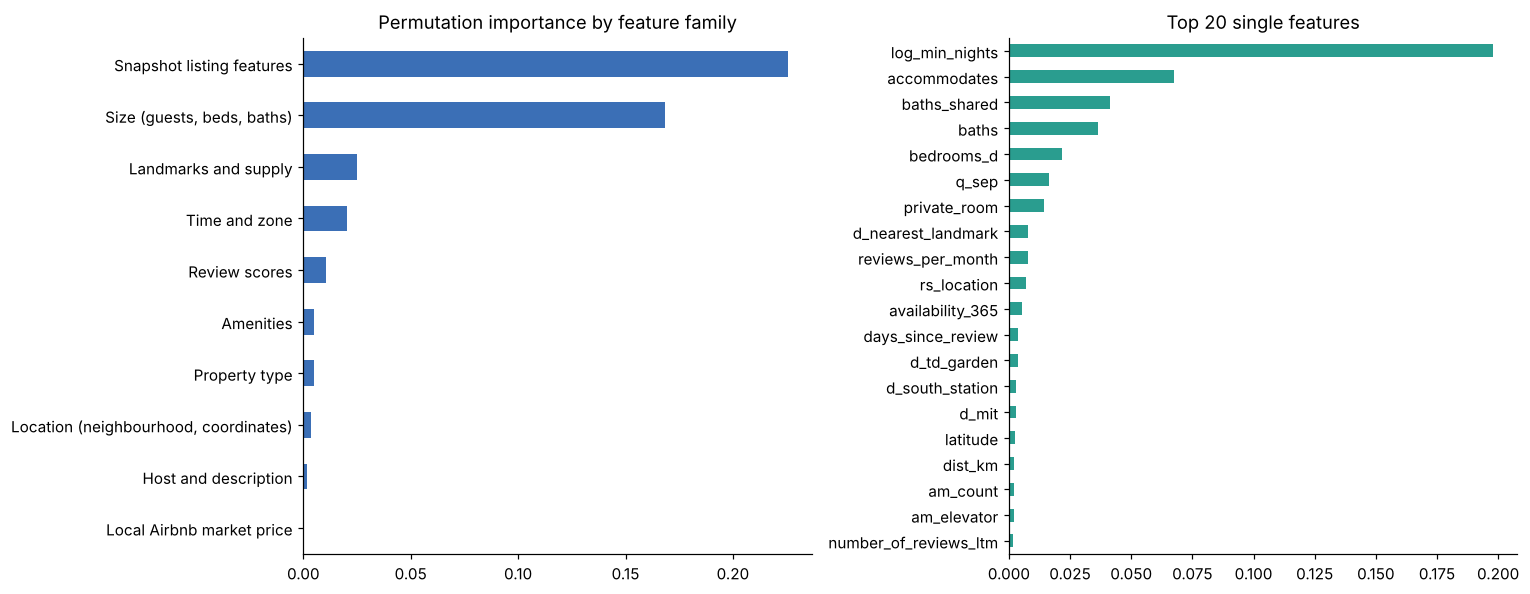

In [14]:
best_row = ladder[ladder["step"] == steps[-1]].sort_values("MAE_$").iloc[0]
BEST = best_row["model"]; best = fitted[(steps[-1], BEST)]
print("best on the full feature set:", BEST, {k: round(best_row[k], 3) for k in ["MAE_$", "R2_log", "within_20%", "MAE_Jun", "MAE_Sep"]})
pi = permutation_importance(best, Xfull.iloc[te], y[te], n_repeats=5, random_state=SEED, scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, Xfull.columns)
fam_imp = imp.groupby(imp.index.map(FAMILY)).sum().sort_values()
top_imp = imp.sort_values().tail(20)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
fam_imp.plot.barh(ax=ax[0], color="#3b6fb6"); ax[0].set_title("Permutation importance by feature family")
top_imp.plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].set_title("Top 20 single features")
plt.tight_layout(); plt.show()

## 9. New listings vs established ones

Listings without reviews are the "new host" case: no review scores, no track record. The error is reported for each group, so the review-based gain isn't overstated.

In [15]:
has_rev = Xfull["has_review_scores"].values[te] == 1
pb = best.predict(Xfull.iloc[te]); p0 = fitted[(steps[0], BEST)].predict(SETS[steps[0]].iloc[te])
cold = pd.DataFrame({
    "listings": [int((~has_rev).sum()), int(has_rev.sum())],
    "MAE Phase 2 features": [mean_absolute_error(np.exp(y[te][m]), np.exp(p0[m])) for m in (~has_rev, has_rev)],
    "MAE Steps 1-2": [mean_absolute_error(np.exp(y[te][m]), np.exp(pb[m])) for m in (~has_rev, has_rev)],
}, index=["no reviews yet", "has reviews"]).round(1)
cold["improvement_%"] = ((1 - cold["MAE Steps 1-2"] / cold["MAE Phase 2 features"]) * 100).round(1)
cold

,listings,MAE Phase 2 features,MAE Steps 1-2,improvement_%
no reviews yet,158,176.5,130.4,26.1
has reviews,1171,130.9,93.7,28.4


## 10. Verdict for Steps 1-2

The ladder tables above give the exact figures for this run.

* **Step 1 is the big win.** Size, bathrooms, property type, amenities and review scores describe *what is being rented*, which the summary file could only guess from titles. Every model improves, by 18% (Lasso) to 27% (LightGBM) in test dollar error, and LightGBM's gain holds in all 5 cross-validation folds.
* **Step 2 adds little.** Landmark distances and nearby supply give LightGBM a tiny gain in cross-validation (about $0.30 a night, in 4 of 5 folds). The local Airbnb market price has almost no importance: the model already knows location from the neighbourhood and coordinates, so the neighbours' median price is redundant. Adding it makes the cross-validated error slightly worse. We keep the landmark features (cheap, interpretable) and drop the market-price feature from the recommended set.
* **Gradient boosting now leads.** With 100+ informative features, LightGBM pulls clearly ahead of Random Forest and Lasso, with CatBoost close behind. This is the opposite of Phase 1, where the thin feature set left little for boosting to find.
* **New listings benefit as much as established ones**, mostly from size and bathrooms, because they have no reviews to lean on.
* **Minimum nights is still the single most important feature,** ahead of guest capacity: it separates nightly stays from discounted monthly rentals.
* **Housing-market data is still missing.** The loader is ready; once the Zillow file is in `data/market/`, rerun the notebook to add it as a rung. Because location is already well covered, the expected value is mostly for comparing *across cities*, not within Boston.

## 11. Export to the interface

In [16]:
best_by_step = ladder.loc[ladder.groupby("step")["MAE_$"].idxmin()].set_index("step")
bundle = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
bundle["phase3"] = {
    "steps": steps, "models": MODELS, "best": BEST,
    "ladder": ladder.round(4).to_dict(orient="records"),
    "family_importance": fam_imp.sort_values(ascending=False).round(5).to_dict(),
    "top_features": top_imp.sort_values(ascending=False).round(5).to_dict(),
    "cold_start": cold.reset_index().rename(columns={"index": "group"}).to_dict(orient="records"),
    "leak_audit": audit.to_dict(orient="records"),
    "n_train": int(len(tr)), "n_test": int(len(te)),
    "n_features": {k: int(v.shape[1]) for k, v in SETS.items()},
    "market_data": zhvi is not None,
    "lgb_params": LGB_BEST,
    "cv_summary": cv_summary.reset_index().round(4).to_dict(orient="records"),
    "cv_paired": paired.reset_index().rename(columns={"index": "step"}).round(3).to_dict(orient="records"),
}
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
print(f"added 'phase3' to interface/data.js ({len(payload) / 1e6:.2f} MB)")
best_by_step[["model", "MAE_$", "R2_log", "within_20%"]].round(3)

added 'phase3' to interface/data.js (0.25 MB)


,model,MAE_$,R2_log,within_20%
step,,,,
0. Phase 2 features,Random Forest,134.710,0.588,40.557
1. + detailed attributes,LightGBM,99.188,0.760,49.737
2. + location context,LightGBM,98.051,0.762,51.091
